# Visual EDA

Write either a function or a class that performs exploratory data analysis (EDA) on a given CSV file.

Run it on both of the cleaned CSV files that you created from your job description crawl:

* `data/processed-jobs-1.csv` (manual cleaning, HW-3.2)
* `data/processed-jobs-2.csv` (LLM-assisted cleaning, HW-3.3)

Your EDA should:

- Explore feature distributions and relationships
- Uncover trends, patterns, and correlations
- Consider incorporating a geospatial analysis where appropriate
  - Folium is a great tool for this: https://realpython.com/python-folium-web-maps-from-data/
- Visualize data effectively
- Be highly visual, with high quality plots
- Briefly compare the two cleaned datasets: which features did each approach extract well, where do they disagree, and which would you trust more for which features?

By focusing on these steps, you'll extract valuable insights and inform deeper analysis of your job descriptions dataset.

## Scope and questions

This EDA asks three questions: **What advertised pay and skill patterns appear in the collected snapshot? How do location and missing work labels affect interpretation? How much do two cleaning approaches change the same postings?**

The manual CSV contains **819 deduplicated postings**, preserving 847 original occurrences. The LLM CSV contains the declared **122-posting availability sample** from Part 3, preserving 133 occurrences. It covers 29/30 search-query categories; Robotics Engineer is absent. It is not a designed probability sample. Both files are profiled separately; all direct extractor comparisons use **the same 122 job keys**.

The crawl was a roughly 25-minute snapshot on **October 30, 2026**, using 30 deliberately selected search titles and a Washington, DC search location. Query balance, search ranking, employer/platform coverage, missing pay, and extraction errors limit representativeness. Dates inferred from posting age do not form a hiring time series. No seasonality, growth, causal salary premium, or population demand is estimated.

In [1]:
import hashlib
import json
from pathlib import Path
import subprocess
import sys

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Code, Markdown, display
import job_eda as eda

eda.style()
REPORTS=Path("reports/eda")
REPORTS.mkdir(parents=True,exist_ok=True)
manual=eda.JobEDA("data/processed-jobs-1.csv","Manual full dataset",eda.COLORS["manual"])
llm=eda.JobEDA("data/processed-jobs-2.csv","LLM sample",eda.COLORS["llm"])
a,b=eda.matched_frames(manual,llm)
manifest=json.loads(Path("reports/llm-sample-selection.json").read_text())
assert set(b.index)=={p["job_key"] for p in manifest["postings"]}
assert len(manual.frame)==819 and len(a)==len(b)==122
print("Input rows:",len(manual.frame),"manual;",len(llm.frame),"LLM")
print("Matched comparison:",len(a),"identical posting identities and descriptions")
print("Crawl UTC range:",manual.frame.crawl_time_utc.min(),"to",manual.frame.crawl_time_utc.max())
print("Libraries: pandas",pd.__version__,"/ Matplotlib",matplotlib.__version__)
print("Offline analysis only: no API/model calls or changes to the cleaned CSVs.")

Matplotlib is building the font cache; this may take a moment.


Input rows: 819 manual; 122 LLM
Matched comparison: 122 identical posting identities and descriptions
Crawl UTC range: 2026-10-30 21:09:19+00:00 to 2026-10-30 21:34:32+00:00
Libraries: pandas 3.0.5 / Matplotlib 3.11.1
Offline analysis only: no API/model calls or changes to the cleaned CSVs.


## Reusable EDA and analysis rules

`JobEDA(csv_path, label, color)` loads either cleaned CSV, validates unique posting keys, decodes JSON list columns, preserves missing categories, derives an EDA-only employment-type display, and generates summaries and a four-panel profile through `.run()`. It counts each vocabulary term once per posting. The implementation is embedded at the end of this HTML.

All figures show their cohort or denominator. “Unknown” remains in work and employment-type denominators. `Contractor` is displayed as `Contract`; title-like employment labels such as `Manager` are displayed as `Other/unrecognized`. Source values are retained, and these display decisions are exported for inspection.

**Core salary sample:** retain positive, finite, USD-labelled annualized bounds/midpoints with ordered bounds; exclude unresolved salary issues, multiple pay bands, domain outliers, and potential survey/non-job postings. Reasons overlap, so their counts must not be summed. Statistical IQR flags alone are not grounds for exclusion. Annualization assumes 2,080 hours, 260 days, 52 weeks or 12 months, as documented in Part 2; it is not guaranteed yearly earnings, particularly for part-time or contract roles. Currency and period assumptions are examined separately.

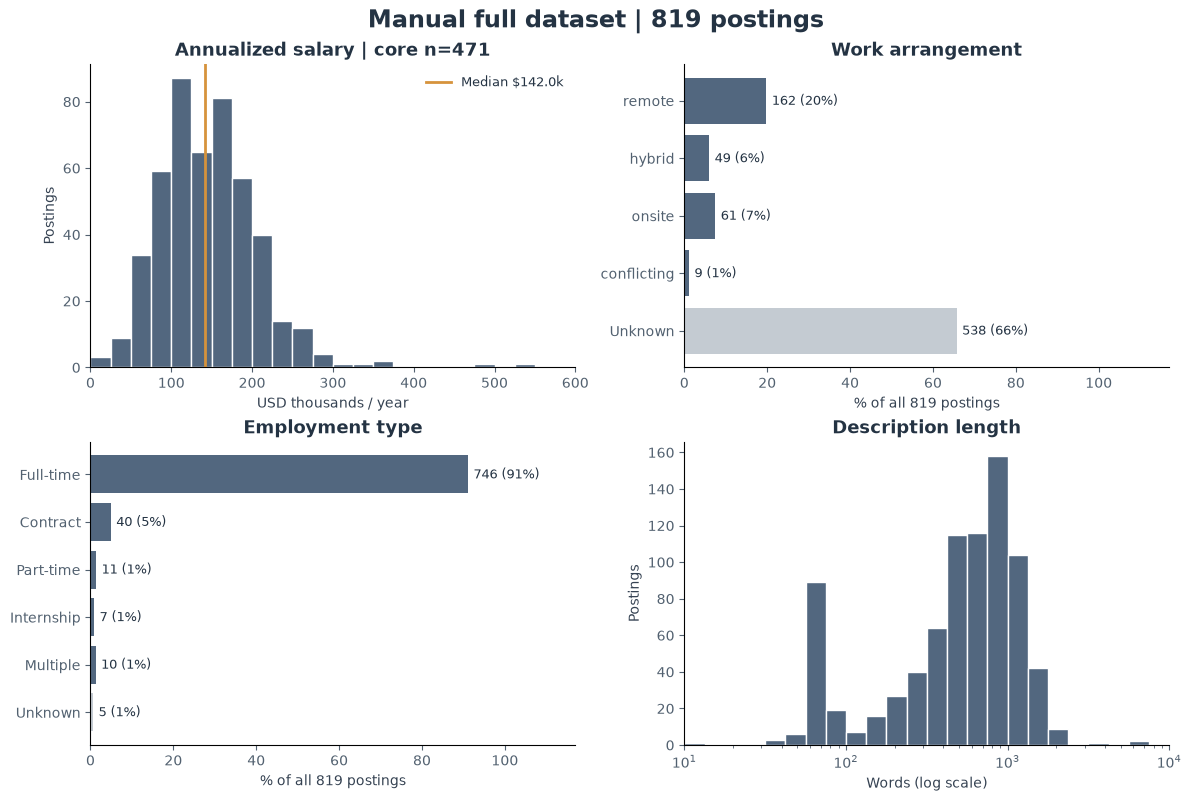

,field,label,observed,denominator,coverage_percent
0,salary_annual_mid,Annualized salary,493,819,60.2%
1,experience_years_min,Numeric experience,415,819,50.7%
2,work_arrangement,Work arrangement,281,819,34.3%
3,visa_sponsorship,Visa sponsorship,97,819,11.8%
4,education_degrees,Education,460,819,56.2%
5,skills,Shared skills / methods,680,819,83.0%
6,industry,Industry,80,819,9.8%
7,experience_level,Title seniority,297,819,36.3%


In [2]:
fig=manual.run("manual");display(fig);plt.close(fig)
display(manual.coverage().style.format({"coverage_percent":"{:.1f}%"}))

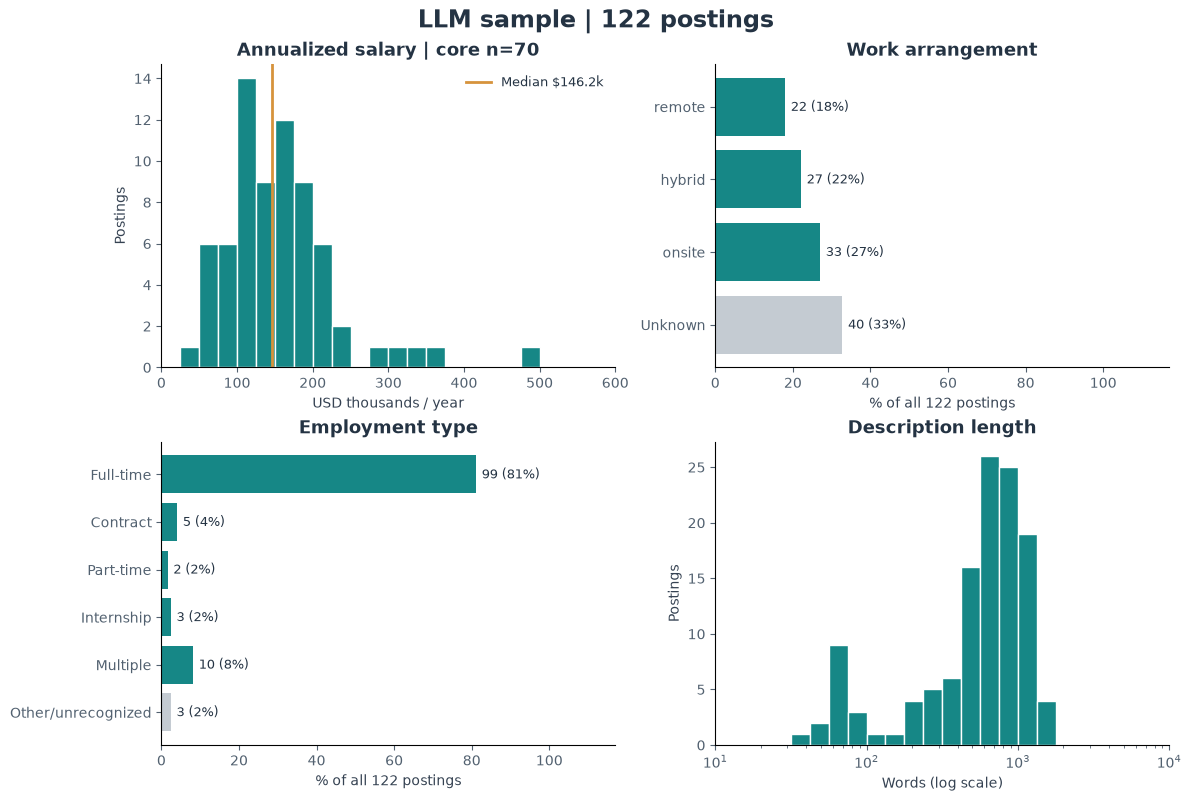

,field,label,observed,denominator,coverage_percent
0,salary_annual_mid,Annualized salary,73,122,59.8%
1,experience_years_min,Numeric experience,71,122,58.2%
2,work_arrangement,Work arrangement,82,122,67.2%
3,visa_sponsorship,Visa sponsorship,11,122,9.0%
4,education_degrees,Education,81,122,66.4%
5,skills,Shared skills / methods,102,122,83.6%
6,industry,Industry,100,122,82.0%
7,experience_level,Title seniority,1,122,0.8%


In [3]:
fig=llm.run("llm");display(fig);plt.close(fig)
display(llm.coverage().style.format({"coverage_percent":"{:.1f}%"}))

### Reading the two profiles

The full manual data are dominated by full-time labels, while work arrangement is frequently unknown. The LLM sample has fewer unknown work labels but also contains invalid employment-type categories. A visually fuller chart is not evidence of better extraction. The salary histograms have the same $25k bins and $0–600k axis, but their **counts and available-pay subsets differ**; they cannot by themselves establish a model-induced salary shift. Description lengths also vary substantially, so mention counts may partly reflect how much text was available.

## 1. Salary distribution and sensitivity to assumptions

The main salary analysis uses the full manual dataset. The table below also shows how results change as pay-period and currency assumptions are removed. The strict subset is much smaller and selected differently; it is a sensitivity description, not a superior representative estimate or confidence interval. Values remain in the CSV even when omitted from a plot.

In [4]:
salary_summary=manual.salary_summary()
display(salary_summary.style.format({"median":"${:,.0f}","q25":"${:,.0f}","q75":"${:,.0f}","mean":"${:,.0f}"}))
exclusion_table=pd.DataFrame({"manual_exclusion_count":manual.exclusions.sum(),"llm_exclusion_count":llm.exclusions.sum()})
display(exclusion_table)
core=manual.salary.salary_annual_mid
strict=salary_summary.set_index("filter").loc["core_explicit_period_currency"]
display(Markdown(f"The manual core has **{len(core)} postings**, a median annualized midpoint of **${core.median():,.0f}**, and an interquartile range of **${core.quantile(.25):,.0f}–${core.quantile(.75):,.0f}**. Requiring explicit period and currency leaves **{int(strict['n'])}** postings with a **${strict['median']:,.0f}** median. Missing-pay and assumption selection remain substantial, even when medians are similar."))

,filter,n,median,q25,q75,mean
0,all_annualized_USD,493,"$142,500","$105,000","$183,800","$147,092"
1,core_single_band,471,"$142,000","$103,250","$181,250","$145,518"
2,core_explicit_period,368,"$140,000","$101,488","$181,625","$143,475"
3,core_explicit_period_currency,47,"$145,000","$96,450","$175,475","$145,019"


,manual_exclusion_count,llm_exclusion_count
missing_or_nonfinite_pay,326,49
not_USD_labelled,323,35
nonpositive_or_inverted_bounds,0,0
unresolved_salary_issue,3,9
multiple_salary_bands,21,3
domain_outlier,0,0
potential_survey_nonjob,2,1


The manual core has **471 postings**, a median annualized midpoint of **$142,000**, and an interquartile range of **$103,250–$181,250**. Requiring explicit period and currency leaves **47** postings with a **$145,000** median. Missing-pay and assumption selection remain substantial, even when medians are similar.

## 2. Salary, experience, and title seniority

The scatter plot uses only jobs with both core pay and a non-outlier numeric experience value. Experience is the parsed minimum advertised requirement, which can compress alternative qualification paths. Seniority boxes use title-derived categories with at least ten available salary observations; jobs without a title label are omitted from those boxes. Whiskers use Matplotlib's usual 1.5-IQR convention and high-value points remain visible.

These are associations within selected advertisements. Company, role, location, pay-period assumptions, and missingness can confound them. Neither the scatter nor the boxes estimate the effect of gaining another year of experience.

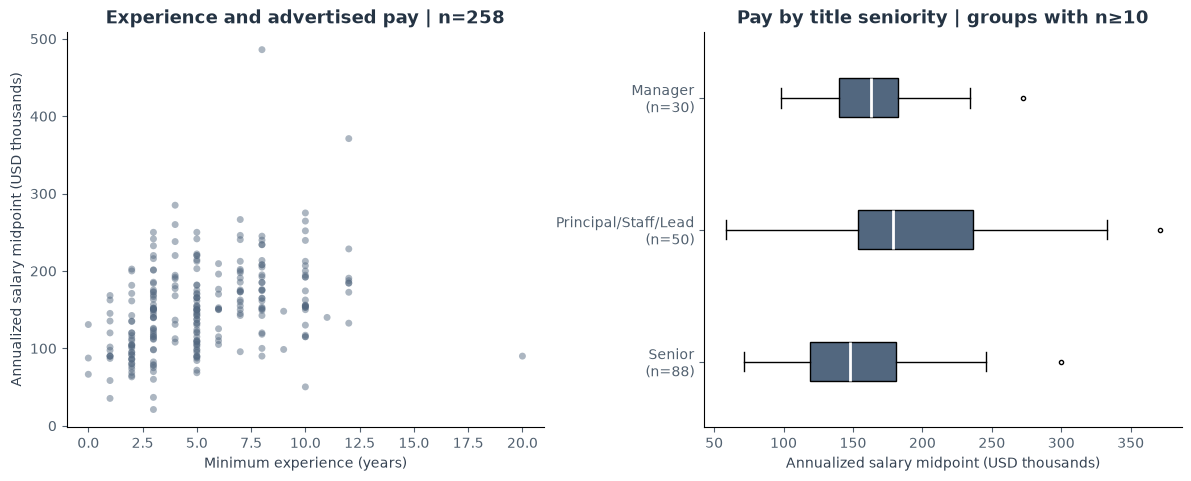

There are **258** complete salary/experience pairs. Their Spearman rank correlation is **0.43**: a positive but imperfect association, with wide salary overlap across experience values and seniority categories.

In [5]:
fig,experience_stats=eda.salary_relationships(manual);display(fig);plt.close(fig)
display(Markdown(f"There are **{experience_stats['paired_postings']}** complete salary/experience pairs. Their Spearman rank correlation is **{experience_stats['spearman_salary_experience']:.2f}**: a positive but imperfect association, with wide salary overlap across experience values and seniority categories."))

## 3. Geographic footprint and the missing-work-label problem

Geography is analyzed at the **recorded US state/DC level**, using only rows with a state, a United States country label, and no multiple-location flag. Every eligible posting contributes once. Rows with missing/ambiguous location stay in the main dataset but are excluded from state charts.

The dataset has no verified coordinates, so a city point map would imply precision the data do not support. State counts and within-state label proportions provide an offline geographic analysis without invented coordinates, geocoding calls, or external map tiles. These are posting-label locations, not where remote employees live or verified employer headquarters. Search design and deduplication also affect the footprint.

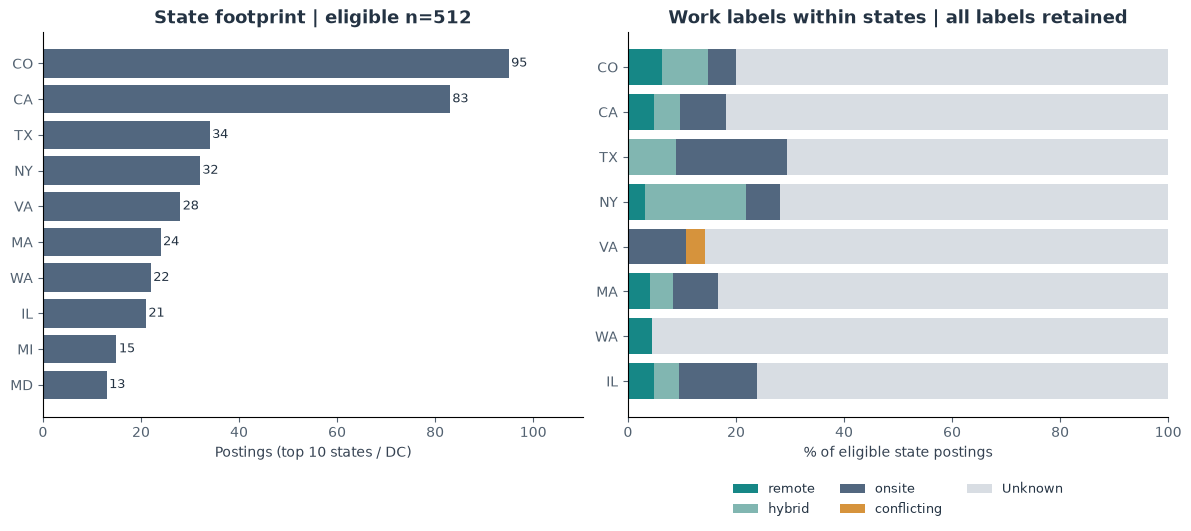

,state,postings
0,CO,95
1,CA,83
2,TX,34
3,NY,32
4,VA,28
5,MA,24
6,WA,22
7,IL,21
8,MI,15
9,MD,13


The state chart contains **512/819** postings; **307** are outside its geographic eligibility rules. Colorado and California have the largest recorded footprints here, but these counts do not rank state labor markets. Across the full dataset, **538/819 (65.7%)** have unknown work arrangement. Remote labels are **162/819 (19.8%)** of all rows, versus **162/272 (59.6%)** among the three clear work labels. Excluding unknowns changes the question and denominator.

In [6]:
fig=eda.geography_plot(manual);display(fig);plt.close(fig)
geo,states=manual.geography()
display(states.head(10))
unknown=int(manual.frame.work_display.eq("Unknown").sum())
remote=int(manual.frame.work_display.eq("remote").sum())
known_three=int(manual.frame.work_display.isin(["remote","hybrid","onsite"]).sum())
display(Markdown(f"The state chart contains **{len(geo)}/{len(manual.frame)}** postings; **{len(manual.frame)-len(geo)}** are outside its geographic eligibility rules. Colorado and California have the largest recorded footprints here, but these counts do not rank state labor markets. Across the full dataset, **{unknown}/{len(manual.frame)} ({unknown/len(manual.frame):.1%})** have unknown work arrangement. Remote labels are **{remote}/{len(manual.frame)} ({remote/len(manual.frame):.1%})** of all rows, versus **{remote}/{known_three} ({remote/known_three:.1%})** among the three clear work labels. Excluding unknowns changes the question and denominator."))

## 4. Skills and methods: vocabulary and query context

The skill vocabulary is the same fixed dictionary used by Part 2. It includes technologies **and methods** such as Statistics and Optimization. Each term counts at most once per posting; multiple terms may occur, so percentages need not sum to 100%. These are text mentions, not necessarily mandatory qualifications.

The left panel describes all 819 manual jobs. The right panel changes both sides to the same 122 jobs and shared vocabulary, preventing the LLM's broader free-text lists from being mistaken for equivalent extra technologies. Broader LLM phrases remain available in its CSV but are outside this chart.

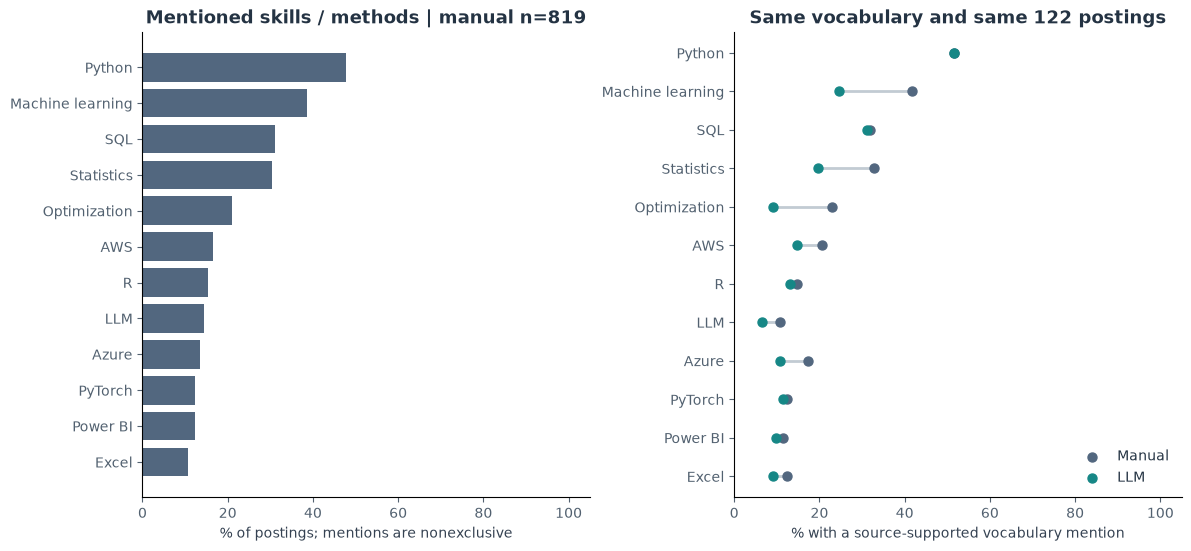

**Python** is the most frequent shared-vocabulary term in the manual data, appearing in **391/819 (47.7%)** postings. Matched extractor differences reflect recognition and normalization choices rather than a change in the underlying 122 descriptions.

In [7]:
fig=eda.skills_plot(manual,llm,a,b);display(fig);plt.close(fig)
skills=pd.read_csv(REPORTS/"skill-mentions.csv")
top=skills.iloc[0]
display(Markdown(f"**{top['skill']}** is the most frequent shared-vocabulary term in the manual data, appearing in **{int(top['full_manual_count'])}/819 ({top['full_manual_count']/819:.1%})** postings. Matched extractor differences reflect recognition and normalization choices rather than a change in the underlying 122 descriptions."))

### Query-group skill profiles

The heatmap shows eight selected search-query groups spanning data, AI, quantitative and biomedical work. Its columns are the nine most frequent shared-vocabulary terms in the full manual data. Each cell's denominator is the row's displayed group size. A posting can belong to several queries, so rows are overlapping groups, not disjoint occupations or independent samples. The collection deliberately queried these roles; differences are descriptive and should not be read as market demand rankings.

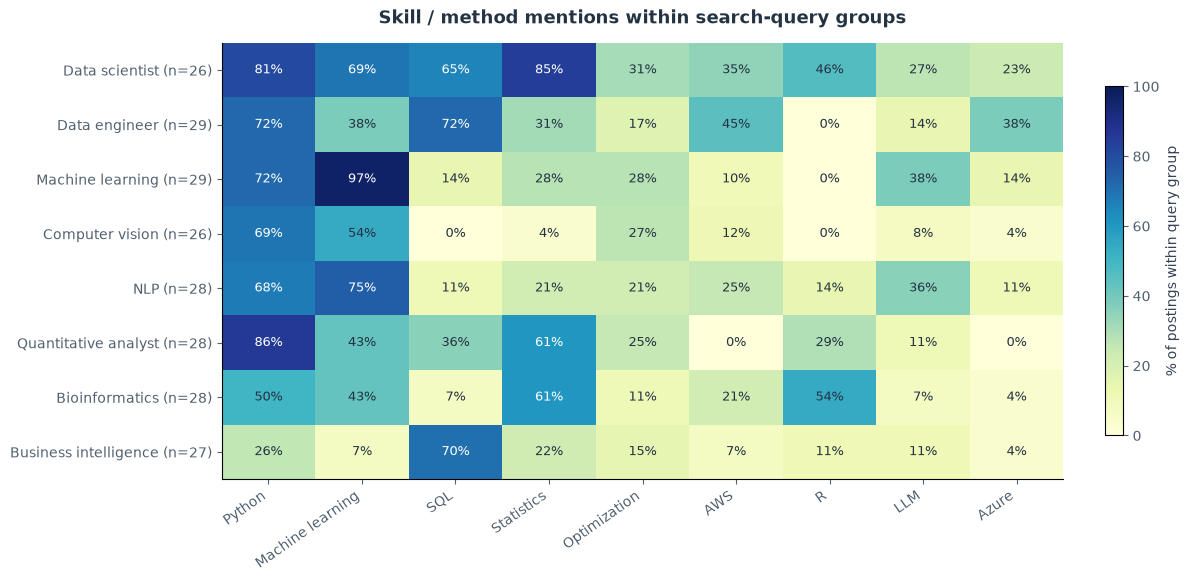

,Python,Machine learning,SQL,Statistics,Optimization,AWS,R,LLM,Azure
Data scientist (n=26),80.8,69.2,65.4,84.6,30.8,34.6,46.2,26.9,23.1
Data engineer (n=29),72.4,37.9,72.4,31.0,17.2,44.8,0.0,13.8,37.9
Machine learning (n=29),72.4,96.6,13.8,27.6,27.6,10.3,0.0,37.9,13.8
Computer vision (n=26),69.2,53.8,0.0,3.8,26.9,11.5,0.0,7.7,3.8
NLP (n=28),67.9,75.0,10.7,21.4,21.4,25.0,14.3,35.7,10.7
Quantitative analyst (n=28),85.7,42.9,35.7,60.7,25.0,0.0,28.6,10.7,0.0
Bioinformatics (n=28),50.0,42.9,7.1,60.7,10.7,21.4,53.6,7.1,3.6
Business intelligence (n=27),25.9,7.4,70.4,22.2,14.8,7.4,11.1,11.1,3.7


SQL is mentioned in **72%** of the selected Data Engineer query group and **70%** of the Business Intelligence group. R appears in **54%** of the Bioinformatics group. The heatmap shows distinct technical profiles within this collection; a zero cell means no dictionary mention was detected, not proof that an occupation never uses that skill.

In [8]:
fig=eda.query_skill_heatmap(manual);display(fig);plt.close(fig)
query_skills=pd.read_csv(REPORTS/"query-skill-percent.csv",index_col=0)
display(query_skills.round(1))

data_sql=float(query_skills.loc["Data engineer (n=29)","SQL"])
bi_sql=float(query_skills.loc["Business intelligence (n=27)","SQL"])
bio_r=float(query_skills.loc["Bioinformatics (n=28)","R"])
display(Markdown(f"SQL is mentioned in **{data_sql:.0f}%** of the selected Data Engineer query group and **{bi_sql:.0f}%** of the Business Intelligence group. R appears in **{bio_r:.0f}%** of the Bioinformatics group. The heatmap shows distinct technical profiles within this collection; a zero cell means no dictionary mention was detected, not proof that an occupation never uses that skill."))

## 5. Multivariate associations

The rank-correlation matrix relates core salary, minimum experience, shared-vocabulary skill count, and description word count. Every cell shows its **own complete-pair count**. Correlations are computed on pairwise ranks, with at least 20 pairs; there is no imputation, significance testing, or causal interpretation. The description and skill-count association helps assess whether longer text provides more opportunities to match vocabulary.

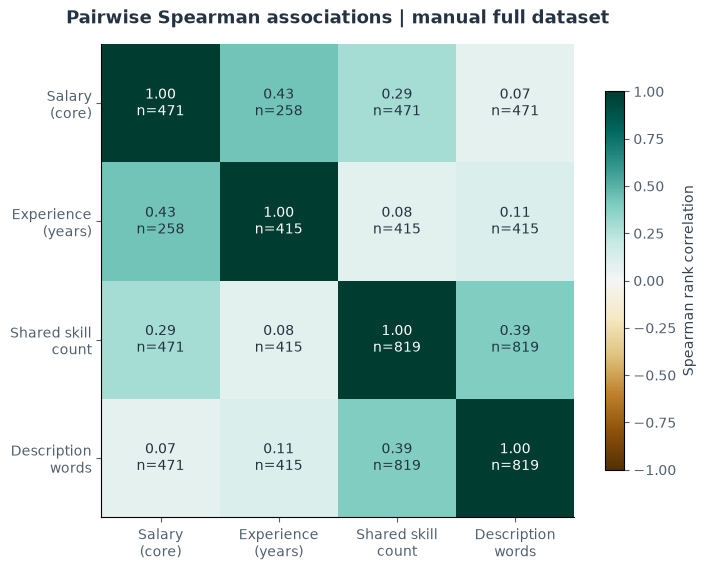

Shared-skill count and description length have a Spearman correlation of **0.39**, while salary and shared-skill count correlate at **0.29** in their available pairs. Longer text may contribute to skill coverage; neither coefficient establishes skill demand or a salary return to acquiring a technology.

In [9]:
fig,correlations,pair_counts=eda.correlation_plot(manual);display(fig);plt.close(fig)
text_skill=float(correlations.loc["shared_skill_count","description_word_count"])
salary_skill=float(correlations.loc["salary_annual_mid","shared_skill_count"])
display(Markdown(f"Shared-skill count and description length have a Spearman correlation of **{text_skill:.2f}**, while salary and shared-skill count correlate at **{salary_skill:.2f}** in their available pairs. Longer text may contribute to skill coverage; neither coefficient establishes skill demand or a salary return to acquiring a technology."))

## 6. Compare the cleaning approaches on identical postings

**All results in this section use the same 122 source identities.** Both descriptions and job/company identity are checked before comparison. Coverage means a nonmissing scalar or nonempty accepted list; it is not an accuracy score. The salary panel is stricter still: it includes only postings meeting core-salary rules in **both** files, so each plotted point compares the same observation. Agreement uses a tolerance of 1% of the manual midpoint or $1, whichever is larger.

The diagonal is equality, not a fitted regression. A common core-salary subset still may retain extraction mistakes. Equal metadata are shared pipeline outputs, not independent confirmation.

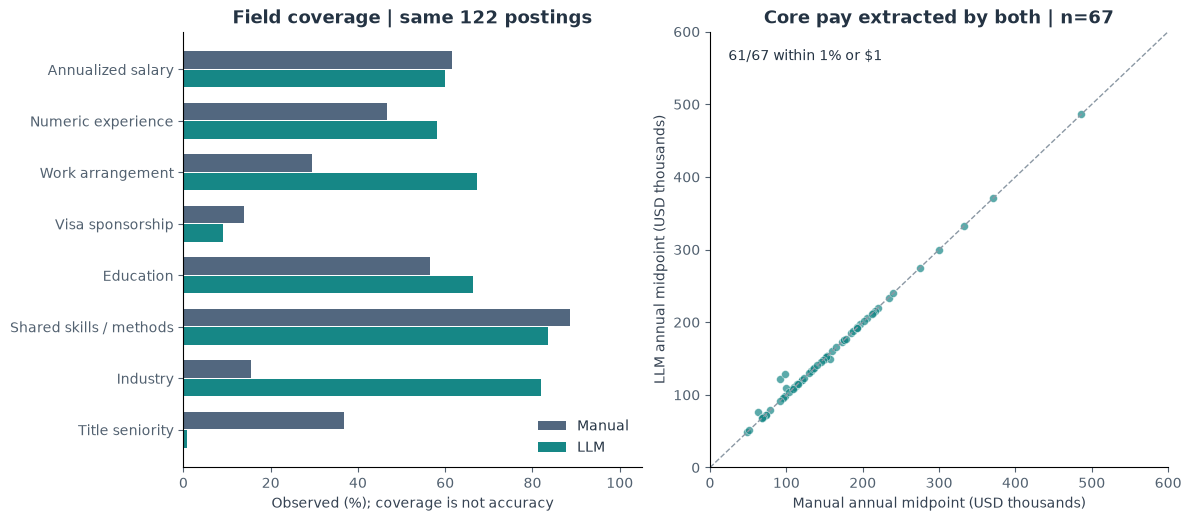

,label,manual_percent,llm_percent
0,Annualized salary,61.5%,59.8%
1,Numeric experience,46.7%,58.2%
2,Work arrangement,29.5%,67.2%
3,Visa sponsorship,13.9%,9.0%
4,Education,56.6%,66.4%
5,Shared skills / methods,88.5%,83.6%
6,Industry,15.6%,82.0%
7,Title seniority,36.9%,0.8%


,cohort,available_pay_n,median_midpoint
0,Manual — full core,471,"$142,000"
1,Manual — matched-cohort core,72,"$135,922"
2,LLM — matched-cohort core,70,"$146,250"


Identical core-pay pairs: 67
Median manual/LLM pay within those exact pairs: 140700.0 140700.0
Work transitions: rows are manual labels, columns are LLM labels.


work_display,remote,hybrid,onsite,conflicting,Unknown
work_display,,,,,
remote,14,2,2,0,3
hybrid,0,9,0,0,0
onsite,0,0,5,0,1
conflicting,0,0,0,0,0
Unknown,8,16,26,0,36


Restricting the manual dataset to the LLM cohort changes its core salary median from **$142,000** to **$135,922**, before changing the extractor. Even within that cohort, the two core-salary counts differ. The identical-pair panel isolates the **67** jointly eligible jobs; their manual and LLM medians are **$140,700** and **$140,700**. Cohort selection, pay availability, and extractor interpretation should be distinguished.

In [10]:
fig,matched_coverage,work_transitions=eda.comparison_plot(manual,llm,a,b);display(fig);plt.close(fig)
display(matched_coverage.style.format({"manual_percent":"{:.1f}%","llm_percent":"{:.1f}%"}))
paired=pd.read_csv(REPORTS/"matched-salary-pairs.csv")
cohort_rows=[]
for label,frame in [("Manual — full core",manual.salary),("Manual — matched-cohort core",manual.salary.loc[manual.salary.job_key.isin(b.index)]),("LLM — matched-cohort core",llm.salary)]:
    cohort_rows.append({"cohort":label,"available_pay_n":len(frame),"median_midpoint":frame.salary_annual_mid.median()})
cohort_table=pd.DataFrame(cohort_rows)
cohort_table.to_csv(REPORTS/"salary-cohort-comparison.csv",index=False)
display(cohort_table.style.format({"median_midpoint":"${:,.0f}"}))
print("Identical core-pay pairs:",len(paired))
print("Median manual/LLM pay within those exact pairs:",paired.manual.median(),paired.llm.median())
print("Work transitions: rows are manual labels, columns are LLM labels.")
display(work_transitions)

display(Markdown(f"Restricting the manual dataset to the LLM cohort changes its core salary median from **${manual.salary.salary_annual_mid.median():,.0f}** to **${cohort_table.iloc[1]['median_midpoint']:,.0f}**, before changing the extractor. Even within that cohort, the two core-salary counts differ. The identical-pair panel isolates the **{len(paired)}** jointly eligible jobs; their manual and LLM medians are **${paired.manual.median():,.0f}** and **${paired.llm.median():,.0f}**. Cohort selection, pay availability, and extractor interpretation should be distinguished."))

### Which output would I trust for which features?

| Feature | Evidence and practical interpretation |
|---|---|
| Source identity, location labels, crawl time | Prefer shared source metadata. Agreement here is expected because both pipelines share these steps. State specificity still limits geography. |
| Annualized salary | Use deterministic unit conversion after checking the original bounds and assumptions. The LLM correctly retained both ends of the marketing salary range where the manual parser kept only the lower value; neither entire salary column is ground truth. Inspect disagreement cases and retain sensitivity summaries. |
| Shared skill/method vocabulary | Manual matching is transparent and consistent for a fixed vocabulary. The LLM can identify broader phrases but may omit dictionary terms. Use common-vocabulary mentions for fair comparisons and do not treat list length as proficiency. |
| Title seniority | Prefer manual title rules here: the matched manual sample has 45 observed values, compared with only one LLM value. The nearly empty LLM field cannot support seniority analysis. |
| Work arrangement, industry and visa | Greater LLM coverage needs source review. Part 3 shows “Full-time” incorrectly interpreted as onsite and TN sponsorship incorrectly labeled unavailable. Unknown does not mean onsite, no sponsorship, or no industry. |

The manual extractor supplies numeric experience more sparsely, while the LLM supplies more experience and industry values. That trade-off is coverage versus potential inference, not proof of higher accuracy. A labeled evaluation would be needed to estimate precision or recall. This analysis does not silently repair the Part 3 CSV.

## Findings, limits and reproducibility

In [11]:
agreement=int(paired.within_tolerance.sum())
findings=f"""
**Observed in this snapshot.** The manual core salary median is **${core.median():,.0f}** across **{len(core)}** available single-band advertisements. Salary and experience show a **{experience_stats['spearman_salary_experience']:.2f}** rank association across **{experience_stats['paired_postings']}** complete pairs. **{top['skill']}** is the most common fixed-vocabulary term. Description length correlates with vocabulary count, so extraction coverage partly depends on text availability.

**Geography and missingness.** Only **{len(geo)}/819** rows support a single-state footprint. Work arrangement is unknown for **{unknown}/819** rows; a remote-work proportion depends strongly on whether those unknowns remain in its denominator. No precise point map, seasonal hiring trend, or regional salary premium is justified by this snapshot.

**Extraction and sampling.** The LLM result is a **122/819 (14.9%) availability sample**, not a second full crawl. Comparisons hold job identities fixed. Among **{len(paired)}** jobs with core pay in both files, **{agreement}** agree within the stated tolerance. Higher model coverage for work and industry does not establish accuracy; sparse model seniority and known semantic errors argue for feature-specific review. Pay missingness and differing eligible-pay subsets also limit median comparisons.

**Reproduce.** Run `python run_part4.py`, then `quarto render HW-3.4-visual-EDA.ipynb --no-execute`. The class runs on both saved CSVs; no API, model, external map service or new download is used. Figures and numeric tables are saved under `reports/eda/`. The source CSV checksums are verified after execution. This part is ready for student review and a separate Git commit; the student pushes it before further work.
"""
display(Markdown(findings))
(REPORTS/"findings.md").write_text(findings,encoding="utf-8")
for obj in [manual,llm]:
    assert hashlib.sha256(obj.path.read_bytes()).hexdigest()==obj.sha256
checks=subprocess.run([sys.executable,"-m","unittest","discover","-s","tests","-p","test_job_eda.py","-q"],capture_output=True,text=True)
print(checks.stdout+checks.stderr);assert checks.returncode==0
summary={"status":"COMPLETE","manual_rows":len(manual.frame),"llm_rows":len(llm.frame),"matched_rows":len(a),
         "manual_core_salary_n":len(manual.salary),"llm_core_salary_n":len(llm.salary),
         "manual_core_salary_median":float(core.median()),"same_core_salary_pairs":len(paired),"salary_pairs_within_tolerance":agreement,
         "salary_experience_complete_pairs":experience_stats["paired_postings"],"salary_experience_spearman":experience_stats["spearman_salary_experience"],
         "manual_geographic_eligible_rows":len(geo),"manual_unknown_work_rows":unknown,
         "plots":sorted(p.name for p in REPORTS.glob("*.png")),"offline_only":True,"source_csvs_unchanged":True,
         "input_sha256":{str(obj.path):obj.sha256 for obj in [manual,llm]},
         "pandas_version":pd.__version__,"matplotlib_version":matplotlib.__version__}
(REPORTS/"analysis-audit.json").write_text(json.dumps(summary,indent=2)+"\n")
print("Part 4 analysis and input integrity checks: passed.")


**Observed in this snapshot.** The manual core salary median is **$142,000** across **471** available single-band advertisements. Salary and experience show a **0.43** rank association across **258** complete pairs. **Python** is the most common fixed-vocabulary term. Description length correlates with vocabulary count, so extraction coverage partly depends on text availability.

**Geography and missingness.** Only **512/819** rows support a single-state footprint. Work arrangement is unknown for **538/819** rows; a remote-work proportion depends strongly on whether those unknowns remain in its denominator. No precise point map, seasonal hiring trend, or regional salary premium is justified by this snapshot.

**Extraction and sampling.** The LLM result is a **122/819 (14.9%) availability sample**, not a second full crawl. Comparisons hold job identities fixed. Among **67** jobs with core pay in both files, **61** agree within the stated tolerance. Higher model coverage for work and industry does not establish accuracy; sparse model seniority and known semantic errors argue for feature-specific review. Pay missingness and differing eligible-pay subsets also limit median comparisons.

**Reproduce.** Run `python run_part4.py`, then `quarto render HW-3.4-visual-EDA.ipynb --no-execute`. The class runs on both saved CSVs; no API, model, external map service or new download is used. Figures and numeric tables are saved under `reports/eda/`. The source CSV checksums are verified after execution. This part is ready for student review and a separate Git commit; the student pushes it before further work.


----------------------------------------------------------------------
Ran 9 tests in 0.050s

OK

Part 4 analysis and input integrity checks: passed.


## Implementation appendix

The complete reusable EDA implementation is embedded here so this HTML includes its loading, filtering, normalization, matching, plotting and reporting logic.

In [12]:
display(Code(Path("job_eda.py").read_text(encoding="utf-8"),language="python"))

"""Offline, reusable visual EDA for a cleaned job CSV; inputs are never modified."""
from collections import Counter
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter
import numpy as np
import pandas as pd

from manual_cleaning import SKILLS

COLORS={'manual':'#52677f','llm':'#168786','accent':'#d6933c','unknown':'#c4cbd2'}
WORK=['remote','hybrid','onsite','conflicting','Unknown']
TYPE=['Full-time','Contract','Part-time','Internship','Temporary','Multiple','Other/unrecognized','Unknown']
FIELDS={'salary_annual_mid':'Annualized salary','experience_years_min':'Numeric experience',
        'work_arrangement':'Work arrangement','visa_sponsorship':'Visa sponsorship',
        'education_degrees':'Education','skills':'Shared skills / methods',
        'industry':'Industry','experience_level':'Title seniority'}
LIST_FIELDS=['skills','search_queries','job_types','education_degrees','benefits']
BOOL_FIELDS=['potential_non_job_posting','multiple_locations','salary_multiple_ranges',
             'salary_domain_outlier','experience_domain_outlier','salary_period_assumed',
             'salary_currency_assumed','quality_review']


def style():
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.titlesize':13,
        'axes.labelsize':10,'figure.facecolor':'white','axes.facecolor':'white',
        'axes.spines.top':False,'axes.spines.right':False,'savefig.facecolor':'white',
        'axes.titleweight':'bold','axes.labelcolor':'#354252','text.color':'#243343',
        'xtick.color':'#526170','ytick.color':'#526170'})


def flag(series):
    return series.map(lambda value:str(value).strip().lower()=='true').fillna(False)


def finish(fig,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    fig.savefig(path,dpi=165,bbox_inches='tight');return fig


def ordered_counts(series,order):
    return series.value_counts().reindex(order,fill_value=0)


def salary_filters(frame):
    """Nonexclusive exclusion flags; overlapping reasons must not be added."""
    numeric=frame[['salary_annual_min','salary_annual_max','salary_annual_mid']]
    return pd.DataFrame({
        'missing_or_nonfinite_pay':numeric.isna().any(axis=1)|~np.isfinite(numeric).all(axis=1),
        'not_USD_labelled':~frame['salary_currency'].eq('USD').fillna(False),
        'nonpositive_or_inverted_bounds':numeric.le(0).any(axis=1)|frame.salary_annual_min.gt(frame.salary_annual_max),
        'unresolved_salary_issue':frame['salary_issue'].notna(),
        'multiple_salary_bands':frame['salary_multiple_ranges'],
        'domain_outlier':frame['salary_domain_outlier'],
        'potential_survey_nonjob':frame['potential_non_job_posting'],
    },index=frame.index).fillna(False)


class JobEDA:
    """Load a cleaned CSV, validate keys/types, summarize it and plot its profile."""
    def __init__(self,csv_path,label,color,output_dir='reports/eda'):
        self.path=Path(csv_path);self.label=label;self.color=color;self.output=Path(output_dir)
        self.output.mkdir(parents=True,exist_ok=True)
        self.sha256=hashlib.sha256(self.path.read_bytes()).hexdigest()
        self.frame=pd.read_csv(self.path)
        if self.frame.job_key.isna().any() or not self.frame.job_key.is_unique:
            raise ValueError('EDA requires nonmissing, unique job_key values.')
        for column in LIST_FIELDS:
            def decode(value):
                parsed=json.loads(value) if isinstance(value,str) else value
                if not isinstance(parsed,list) or any(not isinstance(x,str) for x in parsed):
                    raise ValueError('Expected a JSON string array in '+column)
                return sorted(set(parsed))
            self.frame[column]=self.frame[column].map(decode)
        for column in BOOL_FIELDS:self.frame[column]=flag(self.frame[column])
        for column in ['salary_annual_min','salary_annual_max','salary_annual_mid','experience_years